In [1]:
# import os
# from huggingface_hub import snapshot_download

# # make sure offline mode is off for this one download
# os.environ.pop("HF_HUB_OFFLINE", None)

# path = snapshot_download("Qwen/Qwen2.5-7B-Instruct", cache_dir="/scratch/gandhi.gau/hf_cache/hub")

# print("Downloaded to:", path)
# print("Version (snapshot):", os.path.basename(path))   

In [2]:
# import glob, os

# snap = "/scratch/gandhi.gau/hf_cache/hub/models--Qwen--Qwen2.5-7B-Instruct/snapshots/a09a35458c702b33eeacc393d103063234e8bc28"

# files = sorted(os.listdir(snap))
# print("files:", files)

# shards = glob.glob(f"{snap}/*.safetensors")
# total_gb = sum(os.path.getsize(f) for f in shards) / 1e9
# print("weight shards:", len(shards), "| total size:", round(total_gb, 1), "GB")

In [3]:
# one-time install of the two metric libraries (skipped if they are already there)
import importlib.util, subprocess, sys
for pkg, name in [("bert-score", "bert_score"), ("sacrebleu", "sacrebleu"), ("nltk", "nltk")]:
    if importlib.util.find_spec(name) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
        

In [4]:
import os
os.environ["USE_TF"] = "0"                            # stops TensorFlow warning messages
os.environ["HF_HOME"] = "/scratch/gandhi.gau/hf_cache"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import re, json, glob, time, pickle, datetime
import numpy as np
import pandas as pd
import torch
import transformers
from scipy.stats import binomtest
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt

# record which GPU this run used
print("GPU:", torch.cuda.get_device_name(0))

/home/gandhi.gau/.conda/envs/my_gpu_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA A100 80GB PCIe


In [5]:
CACHE = "/scratch/gandhi.gau/hf_cache/hub"
SPLITS = "/home/gandhi.gau/NLP_Project/paraphrase/splits"
DEBERTA_OUT = "/scratch/gandhi.gau/paraphrase/out_deberta"      # saved DeBERTa models
OUT = "/home/gandhi.gau/NLP_Project/qwen_generation/taskD"
os.makedirs(OUT, exist_ok=True)

# the exact Qwen version we downloaded
HF_ID = "Qwen/Qwen2.5-7B-Instruct"
REVISION = "a09a35458c702b33eeacc393d103063234e8bc28"

SEED = 42
SEEDS = [42, 43, 44, 45, 46]     # the 5 DeBERTa runs

In [6]:
t0 = time.time()
gtok = AutoTokenizer.from_pretrained(HF_ID, revision=REVISION, cache_dir=CACHE,
                                     local_files_only=True, padding_side="left")
gen_model = AutoModelForCausalLM.from_pretrained(HF_ID, revision=REVISION, cache_dir=CACHE,
                                                 local_files_only=True, torch_dtype=torch.bfloat16,
                                                 device_map="cuda").eval()
print("Qwen loaded in", round(time.time() - t0), "s |", round(torch.cuda.memory_allocated() / 1e9, 1), "GB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!



Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]


Loading weights:   0%|          | 1/339 [00:11<1:02:16, 11.05s/it]


Loading weights:   1%|          | 2/339 [00:22<1:03:50, 11.37s/it]


Loading weights:   1%|          | 3/339 [00:23<38:01,  6.79s/it]  


Loading weights:   1%|▏         | 5/339 [00:25<19:03,  3.42s/it]

... (113 outputs left out)


Loading weights:  99%|█████████▊| 334/339 [03:03<00:01,  3.34it/s]


Loading weights:  99%|█████████▉| 336/339 [03:03<00:00,  3.62it/s]


Loading weights: 100%|██████████| 339/339 [03:03<00:00,  1.85it/s]

Qwen loaded in 205 s | 15.2 GB


In [7]:
# Qwen sometimes switches to Chinese, so we block every Chinese/Japanese/Korean token.
# The list is saved the first time, so later runs just load it.
SUPPRESS_FILE = f"{CACHE}/qwen_cjk_suppress.pkl"

if os.path.exists(SUPPRESS_FILE):
    SUPPRESS = pickle.load(open(SUPPRESS_FILE, "rb"))
else:
    CJK = re.compile(r"[\u3040-\u30ff\u3400-\u9fff\uac00-\ud7af\uff00-\uffef]")
    special = set(gtok.all_special_ids)
    texts = gtok.batch_decode([[i] for i in range(len(gtok))])     # all tokens in one call
    SUPPRESS = [i for i, t in enumerate(texts) if i not in special and CJK.search(t)]
    pickle.dump(SUPPRESS, open(SUPPRESS_FILE, "wb"))

print("blocked tokens:", len(SUPPRESS))

blocked tokens: 30927


In [8]:
# same sampling settings as the rest of the team
GEN_CFG = dict(temperature=0.7, top_p=0.9, top_k=40, max_new_tokens=128)

def generate_batch(system_prompt, inputs, temperature=None):
    """
    Send a batch of sentences to Qwen with the same system prompt and return its replies.
    """
    prompts = []
    for text in inputs:
        msgs = [{"role": "system", "content": system_prompt}, {"role": "user", "content": text}]
        prompts.append(gtok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))

    # same settings as the team, unless a different temperature is asked for
    cfg = dict(GEN_CFG)
    if temperature is not None:
        cfg["temperature"] = temperature

    enc = gtok(prompts, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        out = gen_model.generate(**enc, do_sample=True, pad_token_id=gtok.pad_token_id,
                                 suppress_tokens=SUPPRESS, **cfg)

    # keep only the new tokens, not the prompt
    new = out[:, enc.input_ids.shape[1]:]
    return [t.strip() for t in gtok.batch_decode(new, skip_special_tokens=True)]

torch.manual_seed(SEED)
print(generate_batch("Paraphrase the sentence. Output only the paraphrase.", ["The cat sat on the mat."])[0])

The feline perched on the rug.


In [9]:
snap = f"{CACHE}/models--Qwen--Qwen2.5-7B-Instruct/snapshots/{REVISION}"
cfg = json.load(open(f"{snap}/config.json"))

print("model:        ", HF_ID)
print("revision:     ", REVISION)
print("transformers: ", transformers.__version__, "| torch:", torch.__version__)
print("parameters:   ", f"{sum(p.numel() for p in gen_model.parameters()) / 1e9:.2f}B")
for k in ["num_hidden_layers", "hidden_size", "num_attention_heads", "num_key_value_heads",
          "vocab_size", "max_position_embeddings", "torch_dtype"]:
    print(f"{k:24s}", cfg.get(k))

model:         Qwen/Qwen2.5-7B-Instruct
revision:      a09a35458c702b33eeacc393d103063234e8bc28
transformers:  5.22.1 | torch: 2.14.1+cu126
parameters:    7.62B
num_hidden_layers        28
hidden_size              3584
num_attention_heads      28
num_key_value_heads      4
vocab_size               152064
max_position_embeddings  32768
torch_dtype              bfloat16


# Task D: Near-miss sentences (hard negatives)

In this notebook, Qwen takes a real sentence from our test sets and makes a small edit that changes its meaning while keeping almost all of its words. Eg: "Anna emailed Ben" becomes "Ben emailed Anna". This is the same kind of trap as the PAWS non-paraphrases, so every pair we create here has the true label 0 (not a paraphrase).

Then we check 2 things:
1. Did Qwen do the job: Filter out pairs where the edit did not happen, and measure how similar the new sentence is to the original (BERTScore and BLEU).
2. Do the classifiers get fooled: Every pair is scored by DeBERTa (the winning model), the debiased DeBERTa and Qwen. The fool rate is the share of near-misses a judge wrongly calls a paraphrase, so lower is better. The dataset's own human paraphrases of the same sentences serve as a control.

No model is trained here, all judges are used as they are, and only the test splits are used.

## Choosing the source sentences
The starting sentences come from the test pairs labelled 1 (real paraphrases): from each pair, the first sentence (`sentence1`) is taken. These are clean, natural sentences, and each one already has a human-written paraphrase in the dataset. We use all 279 from MRPC and a random 1,000 each from QQP and PAWS, so no single dataset dominates the results.

Each sentence keeps its row number (`idx`) from the test file, so every near-miss can be matched back to its original pair.

In [10]:
rows = []
for ds, n in [("mrpc", None), ("qqp", 1000), ("paws", 1000)]:
    df = pd.read_csv(f"{SPLITS}/{ds}_test.csv", keep_default_na=False)
    df = df.reset_index().rename(columns={"index": "idx"})    # row number in the test file

    pos = df[df["label"] == 1]
    if n is not None and len(pos) > n:
        pos = pos.sample(n, random_state=SEED)                 # same sample every time

    for _, r in pos.iterrows():
        rows.append({"dataset": ds, "idx": r["idx"], "source": str(r["sentence1"])})

src = pd.DataFrame(rows)
print(src.groupby("dataset").size())

dataset
mrpc     279
paws    1000
qqp     1000
dtype: int64


## Three kinds of edits
To make the near-misses varied (and closer to PAWS), Qwen is asked for one of 3 edits:
- **number:** change one number, date or amount (e.g. "born in 1970" -> "born in 1971")
- **swap:** swap two names, places, objects or roles (e.g. "Anna emailed Ben" -> "Ben emailed Anna")
- **negation:** flip the meaning by adding or removing a "not" or "never"

Sentences that contain a number get the number edit. The rest alternate between swap and negation. Each prompt tells Qwen to change as few words as possible, and to reply "NONE" if the edit does not make sense for that sentence. We remove those later.

In [11]:
COMMON = (" Keep every other word the same and keep the same style. "
          "A statement must stay a statement, and a question must stay a question. "
          "The result must be grammatical and natural. "
          "If this change is not possible, output only NONE. "
          "Write in English and output only the new sentence.")

PROMPTS = {
    "number": "Change one number, date or amount in the sentence so that its meaning changes." + COMMON,
    "swap": ("Swap the positions of two names, places, objects or roles that are already in the sentence, "
             "so that its meaning changes. Do not replace them with new words." + COMMON),
    "negation": "Add or remove one negation, such as 'not' or 'never', so that the sentence means the opposite." + COMMON,
}

# decide which edit each sentence gets
def pick_edit(position, sentence):
    if re.search(r"\d", sentence):
        return "number"
    return "swap" if position % 2 == 0 else "negation"

src["edit_type"] = [pick_edit(i, s) for i, s in enumerate(src["source"])]
print(pd.crosstab(src["dataset"], src["edit_type"]))

edit_type  negation  number  swap
dataset                          
mrpc             81     100    98
paws            292     419   289
qqp             440     110   450


In [12]:
# small test before the full run: 2 sentences per edit type
test = src.groupby("edit_type").head(2)
for edit, group in test.groupby("edit_type"):
    torch.manual_seed(SEED)
    outs = generate_batch(PROMPTS[edit], group["source"].tolist())
    for s, o in zip(group["source"], outs):
        print(f"[{edit}]\n  SRC: {s}\n  NEW: {o}\n")

[negation]
  SRC: The AFL-CIO is waiting until October to decide if it will endorse a candidate .
  NEW: The AFL-CIO is not waiting until October to decide if it will endorse a candidate.

[negation]
  SRC: This integrates with Rational PurifyPlus and allows developers to work in supported versions of Java , Visual C # and Visual Basic .NET.
  NEW: This integrates with Rational PurifyPlus and does not allow developers to work in supported versions of Java, Visual C# and Visual Basic .NET.



[number]
  SRC: The top rate will go to 4.45 percent for all residents with taxable incomes above $ 500,000 .
  NEW: The top rate will go to 4.45 percent for all residents with taxable incomes above $ 1 million .

[number]
  SRC: The only announced Republican to replace Davis is Rep. Darrell Issa of Vista , who has spent $ 1.71 million of his own money to force a recall .
  NEW: The only announced Republican to replace Davis is Rep. Darrell Issa of Vista , who has spent $ 1.72 million of his own money to force a recall .



[swap]
  SRC: He said the foodservice pie business doesn 't fit the company 's long-term growth strategy .
  NEW: He said the automotive pie business doesn't fit the company's long-term growth strategy.

[swap]
  SRC: Wal-Mart said it would check all of its million-plus domestic workers to ensure they were legally employed .
  NEW: Wal-Mart said it would check all of its million-plus domestic products to ensure they were legally employed.



## Generating the near-misses
The sentences are sent to Qwen in batches of 128, grouped by edit type so that each batch uses a single prompt. Each batch has its own fixed seed, so the run gives the same outputs when repeated with the same software setup. If the output file already exists, the cell loads it instead of generating again.

In [13]:
GEN_FILE = f"{OUT}/taskD_generated.csv"
BS = 128

if os.path.exists(GEN_FILE):
    gen = pd.read_csv(GEN_FILE, keep_default_na=False)
    print("Loaded saved generations:", len(gen))
else:
    parts = []
    batch_no = 0
    t0 = time.time()
    for edit, group in src.groupby("edit_type"):
        group = group.copy()
        outputs = []
        for i in range(0, len(group), BS):
            torch.manual_seed(SEED + batch_no)          # fixed seed for each batch
            outputs += generate_batch(PROMPTS[edit], group["source"].iloc[i:i + BS].tolist())
            batch_no += 1
        group["near_miss"] = outputs
        parts.append(group)
        print(f"{edit}: {len(group)} done")

    gen = pd.concat(parts).sort_values(["dataset", "idx"]).reset_index(drop=True)
    gen.to_csv(GEN_FILE, index=False)
    print(f"Generated {len(gen)} sentences in {time.time() - t0:.0f} s")


Loaded saved generations: 2279


In [14]:
# save how this was generated
meta = {"task": "D: near-miss hard negatives", "model": HF_ID, "revision": REVISION,
        "dtype": "bfloat16", "gen_config": GEN_CFG, "seed": SEED, "batch_size": BS,
        "prompts": PROMPTS, "date": datetime.datetime.now().isoformat(timespec="seconds")}
json.dump(meta, open(f"{OUT}/taskD_metadata.json", "w"), indent=1)

## Cleaning and filtering
Not every output is a usable near-miss, so a pair is removed if:
- the output is empty, "NONE", an exact copy of the source, or starts with extra text such as "Here is…"
- the sentence type changed (a question became a statement, or the other way round)
- the length changed a lot (less than 0.7 or more than 1.4 times the source length)
- the two sentences share less than 70% of their words (Jaccard overlap), since the pair is then no longer a near-miss
- the requested edit did not actually happen:
  - **number:** none of the numbers changed (commas are ignored, so "1,000" and "1000" count as the same)
  - **negation:** the meaning did not flip. Negation words (not, never, no, …) are counted, and the count must go up or down by an odd number, so "not" -> "never" does not count as a flip.
  - **swap:** the words changed too much, or nothing really moved (the words are still in the same order)

Before filtering, the formatting is also matched to each dataset. MRPC and PAWS are written in Penn Treebank style, with spaces around punctuation and split contractions, while Qwen writes normal text. A classifier could pick up on this difference instead of the meaning, so Qwen's sentences for these two datasets are passed through NLTK's standard Treebank tokenizer. QQP already uses normal text, so its sentences are left as they are.

In [15]:
from nltk.tokenize import TreebankWordTokenizer
treebank = TreebankWordTokenizer()

def jaccard(s1, s2):
    # shared words / all unique words, same as in our EDA and baseline
    w1 = set(re.findall(r"\w+", s1.lower()))
    w2 = set(re.findall(r"\w+", s2.lower()))
    if len(w1 | w2) == 0:
        return 0.0
    return len(w1 & w2) / len(w1 | w2)

def normalise(text, ds):
    # MRPC and PAWS are written in Penn Treebank style,
    # so we put Qwen's sentence through the standard Treebank tokenizer to match it
    if ds in ("mrpc", "paws"):
        text = " ".join(treebank.tokenize(text))
        if ds == "mrpc":
            # MRPC keeps plain double quotes instead of `` and ''
            text = text.replace("``", '"').replace("''", '"')
    return " ".join(text.split())

In [16]:
NEG_WORDS = {"not", "no", "never", "none", "nobody", "nothing", "neither", "nor", "cannot", "without"}

def negations(s):
    # negation words, plus words ending in n't
    words = re.findall(r"[\w']+", s.lower())
    return [w for w in words if w in NEG_WORDS or w.endswith("n't")]

In [ ]:
# make sure every output is text, then match MRPC/PAWS spacing style
gen["near_miss"] = gen["near_miss"].astype(str)
gen["near_miss_clean"] = [normalise(t, ds) for t, ds in zip(gen["near_miss"], gen["dataset"])]

# s = original sentence, g = Qwen's edited sentence (extra spaces at the ends removed)
s = gen["source"].str.strip()
g = gen["near_miss_clean"].str.strip()

# one True or False column per check (True = problem found)
flags = pd.DataFrame(index=gen.index)

# Qwen returned nothing, or said NONE because the edit was not possible
flags["empty_or_none"] = (g == "") | (g.str.upper().str.strip(". ") == "NONE")

# Qwen returned the same sentence, so nothing changed
flags["copy"] = g.str.lower() == s.str.lower()

# Qwen added chatty text 
flags["extra_text"] = g.str.contains(r"^(?:here|sure|certainly)\b|paraphrase:|sentence:", case=False, regex=True)

# the sentence type changed (a question became a statement, or a statement became a question)
flags["type_changed"] = s.str.endswith("?") != g.str.endswith("?")

# output is much shorter or longer than the source 
ratio = g.str.len() / s.str.len()
flags["length_change"] = (ratio < 0.7) | (ratio > 1.4)

# word overlap with the source, below 0.7 it's no longer a near-miss
gen["overlap"] = [jaccard(a, b) for a, b in zip(s, g)]
flags["low_overlap"] = gen["overlap"] < 0.7

## Checking if the edit happened

In [18]:
def numbers(s):
    # numbers in the sentence, with commas removed so "1,000" and "1000" count as the same
    return re.findall(r"\d+(?:\.\d+)?", s.replace(",", ""))

def words(s):
    return re.findall(r"\w+", s.lower())

In [ ]:
# did the requested edit actually happen
edit_missing = []
for edit, a, b in zip(gen["edit_type"], s, g):
    if edit == "number":
        # at least one number must be different
        edit_missing.append(numbers(a) == numbers(b))
    elif edit == "negation":
        # meaning only flips if the number of negations goes up or down by an odd amount
        # ("not" -> "never" or "cannot" -> "can not" do not count)
        edit_missing.append((len(negations(a)) - len(negations(b))) % 2 == 0)
    else:
        # swap: almost the same words, but in a different order
        edit_missing.append(jaccard(a, b) < 0.85 or words(a) == words(b))
flags["edit_missing"] = edit_missing

In [ ]:
# drop old flag columns first, so re-running this cell does not duplicate them
gen = gen.drop(columns=list(flags.columns) + ["keep"], errors="ignore")
gen["keep"] = ~flags.any(axis=1)
gen = pd.concat([gen, flags], axis=1)
gen.to_csv(f"{OUT}/taskD_all_with_flags.csv", index=False)

In [ ]:
# Number of pairs each check removed, per dataset
summary = flags.groupby(gen["dataset"]).sum()
summary["kept"] = gen.groupby("dataset")["keep"].sum()
summary["total"] = gen.groupby("dataset").size()
summary["kept_%"] = (summary["kept"] / summary["total"] * 100).round(1)
summary

,empty_or_none,copy,extra_text,type_changed,length_change,low_overlap,edit_missing,kept,total,kept_%
dataset,,,,,,,,,,
mrpc,1,4,0,0,4,7,72,205,279,73.5
paws,2,16,0,0,4,25,220,771,1000,77.1
qqp,16,5,0,28,20,129,450,505,1000,50.5


In [22]:
clean = gen[gen["keep"]].reset_index(drop=True)
clean["label"] = 0      # every near-miss is a non-paraphrase by design
clean.to_csv(f"{OUT}/taskD_clean.csv", index=False)

print("Usable near-miss pairs:", len(clean))
print(pd.crosstab(clean["dataset"], clean["edit_type"], margins=True))

# a few random examples 
for _, r in clean.sample(6, random_state=SEED).iterrows():
    print(f"\n[{r.dataset} | {r.edit_type}]\n  SRC: {r.source}\n  NEW: {r.near_miss_clean}")

Usable near-miss pairs: 1481
edit_type  negation  number  swap   All
dataset                                
mrpc             50      82    73   205
paws            177     344   250   771
qqp             281      98   126   505
All             508     524   449  1481

[mrpc | swap]
  SRC: Citigroup Inc . C.N , the world 's largest financial services company , on Wednesday promoted Marjorie Magner to chairman and chief executive of its global consumer group .
  NEW: Citigroup Inc . C.N , the world 's largest financial services company , on Wednesday promoted Thomas Vartanian to chairman and chief executive of its global consumer group .

[paws | number]
  SRC: The book `` Housemeeting '' by Lano and Woodley was published by Penguin Books in 1996 with illustrations by Woodley and a foreword by Andrew Denton .
  NEW: The book `` Housemeeting `` by Lano and Woodley was published by Penguin Books in 1997 with illustrations by Woodley and a foreword by Andrew Denton .

[qqp | negation]
  SR

## Second cleaning pass (a closer look at the swaps):
The small test before the full run already showed a problem with the swaps: neither of the two swap outputs was a real swap. Qwen replaced one word instead of swapping two ("foodservice pie business" -> "automotive pie business", and "domestic workers" -> "domestic products", which no longer makes sense). The first-pass check only required most of the words to stay the same, so pairs like these got through, and the Wal-Mart sentence is still in the cleaned set above.

To fix this, every swap goes through two stricter tests: it must use exactly the same words as the source, and it must not simply reorder items in a list. The cells below flag the pairs that fail and print five examples of each problem before anything is removed.

In [23]:
import difflib

def is_real_swap(a, b):
    # A real swap keeps exactly the same words and only changes their order
    return sorted(words(a)) == sorted(words(b))

In [ ]:
def list_reorder(a, b):
    # Checks whether the only change is items in a list trading places.
    # The meaning stays the same, so such pair is really a paraphrase.
    src_words = a.split()
    new_words = b.split()

    # parts of the sentence that differ
    matcher = difflib.SequenceMatcher(None, src_words, new_words)
    changes = []
    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag != "equal":
            changes.append((src_words[i1:i2], new_words[j1:j2]))

    # In a reorder, a chunk is only moved: it disappears in one place
    # and reappears in another, without any word being replaced
    only_moved = all(len(old) == 0 or len(new) == 0 for old, new in changes)

    # In a list, the moved chunk starts or ends with a comma, "and" or "or"
    list_words = (",", "and", "or")
    in_list = False
    for old, new in changes:
        chunk = old if old else new
        if chunk[0] in list_words or chunk[-1] in list_words:
            in_list = True

    return only_moved and in_list

In [25]:
# Label each pair: swaps that fail a check get the reason they failed, and every other pair is left blank
reason = []
for edit, a, b in zip(clean["edit_type"], clean["source"], clean["near_miss_clean"]):
    if edit == "swap" and not is_real_swap(a, b):
        reason.append("word replaced, not swapped")
    elif edit == "swap" and list_reorder(a, b):
        reason.append("list reordered, same meaning")
    else:
        reason.append("")
clean["removed_because"] = reason

# Save the first-pass pairs so the change can be traced later
clean.to_csv(f"{OUT}/taskD_clean_first_pass.csv", index=False)

# Number of pairs each check removes, per dataset
removed = clean[clean["removed_because"] != ""]
display(removed.groupby(["removed_because", "dataset"]).size().unstack(fill_value=0))

# A few examples of each problem
for why, part in removed.groupby("removed_because"):
    print(f"\n{why}:")
    for _, r in part.sample(5, random_state=SEED).iterrows():
        print(f"  SRC: {r['source']}\n  NEW: {r['near_miss_clean']}\n")

dataset,mrpc,paws,qqp
removed_because,,,
"list reordered, same meaning",5,44,8
"word replaced, not swapped",42,72,50



list reordered, same meaning:
  SRC: The delegates said raising and distributing funds has been complicated by the U.S. crackdown on jihadi charitable foundations , bank accounts of terror-related organizations and money transfers .
  NEW: The delegates said raising and distributing funds has been complicated by the U.S. crackdown on bank accounts of terror-related organizations , jihadi charitable foundations and money transfers .

  SRC: In addition to artificial insemination by rams , natural insemination and embryo transfers have been used in sheep breeding programs for many years in Australia and New Zealand .
  NEW: In addition to artificial insemination by rams , natural insemination and embryo transfers have been used in sheep breeding programs for many years in New Zealand and Australia .

  SRC: Though binary operators including but not limited to exclusive or and set union may be used .
  NEW: Though binary operators including but not limited to set union and exclusive or m

The output confirms what the small test suggested, and also shows a second problem:

1. **Replaced words are not swaps, so their labels cannot be trusted:** As in the test, Qwen often changed one word instead of swapping two. Some of these edits change the meaning ("six pack abs" -> "six pack legs"), others do not ("across the Sydney" -> "across the city of Sydney"), and a few are near-swaps that changed a word count, like the River Juruá example.
2. **List reorders keep the meaning:** Here, items in a list simply trade places ("Dick Rathmann and Ed Elisian" -> "Ed Elisian and Dick Rathmann", "Australia and New Zealand" -> "New Zealand and Australia"). These pairs are really paraphrases but were labelled 0, so a judge that correctly called them paraphrases would have been counted as fooled.

Both groups are removed. A few valid near-misses are lost along the way, but there is no reliable way to separate them automatically, and keeping pairs with wrong labels would distort every result that follows. A smaller set with trustworthy labels is preferred over a larger one with hidden errors.

In [26]:
# Keep only the pairs that pass both checks
clean = clean[clean["removed_because"] == ""].drop(columns="removed_because").reset_index(drop=True)
clean.to_csv(f"{OUT}/taskD_clean.csv", index=False)

print("Usable near-miss pairs after the second pass:", len(clean))
print(pd.crosstab(clean["dataset"], clean["edit_type"], margins=True))

Usable near-miss pairs after the second pass: 1260
edit_type  negation  number  swap   All
dataset                                
mrpc             50      82    26   158
paws            177     344   134   655
qqp             281      98    68   447
All             508     524   228  1260


After the second pass, 1,260 near-miss pairs remain: 164 pairs with a replaced word and 57 list reorders were removed. Every remaining swap now uses exactly the same words as its source, just like the PAWS traps. A few swaps may still keep the meaning, eg: when two options joined by "or" trade places, so the hand check below measures how often this happens.

## Hand check
The filters only catch obvious failures, so a sample of 60 pairs (20 per dataset) is also checked by hand to see how often the meaning really changed. They are saved to `taskD_handcheck.csv` with an empty `meaning_changed` column, where each pair gets a 1 if the meaning changed and a 0 if it still means the same. After the file is filled in, re-running the cell below shows the result. The file is only created once, so the answers are never overwritten.

In [3]:
HAND_FILE = f"{OUT}/taskD_handcheck.csv"

if not os.path.exists(HAND_FILE):
    # 20 random pairs from each dataset
    sample = clean.groupby("dataset").sample(n=20, random_state=SEED)
    sample = sample[["dataset", "idx", "edit_type", "source", "near_miss_clean"]].copy()
    sample["meaning_changed"] = ""
    sample.to_csv(HAND_FILE, index=False)
    print("Saved", len(sample), "pairs to", HAND_FILE, "for checking")
    
hand = pd.read_csv(HAND_FILE, keep_default_na=False)
filled = hand[hand["meaning_changed"].astype(str).str.strip() != ""]
if len(filled) > 0:
    filled = filled.assign(meaning_changed=filled["meaning_changed"].astype(int))
    print(f"Checked {len(filled)} pairs: meaning really changed in {filled['meaning_changed'].mean():.1%}")
    display(filled.groupby(["dataset", "edit_type"])["meaning_changed"].mean().round(2))
    
    # Swaps get a separate count, since most of the errors come from them
    swaps = filled[filled["edit_type"] == "swap"]
    print(f"\nSwaps that changed the meaning: {swaps['meaning_changed'].sum()} of {len(swaps)}")

    # Print the faulty pairs so the errors can be seen directly
    print("\nPairs where the meaning did not change:")
    for _, r in filled[filled["meaning_changed"] == 0].iterrows():
        print(f"  [{r['dataset']} | {r['edit_type']}]")
        print(f"  SRC: {r['source']}")
        print(f"  NEW: {r['near_miss_clean']}\n")
else:
    print("Hand check not filled in yet")

Checked 60 pairs: meaning really changed in 88.3%


dataset  edit_type
mrpc     negation     1.00
         number       1.00
         swap         0.00
paws     negation     1.00
         number       1.00
         swap         0.80
qqp      negation     0.91
         number       1.00
         swap         0.20
Name: meaning_changed, dtype: float64


Swaps that changed the meaning: 5 of 11

Pairs where the meaning did not change:
  [mrpc | swap]
  SRC: But Virgin wants to operate Concorde on routes to New York , Barbados and Dubai .
  NEW: But Virgin wants to operate Concorde on routes to Dubai , Barbados and New York .

  [paws | swap]
  SRC: The sites were selected at Maiduguri , Kaduna , Lagos , Minna , Kano and Oshogbo .
  NEW: The sites were selected at Oshogbo , Kaduna , Lagos , Minna , Kano and Maiduguri .

  [qqp | swap]
  SRC: How do you delete an instagram account when you don't remember the password or username?
  NEW: How do you delete an Instagram account when you don't remember the username or password?

  [qqp | swap]
  SRC: Who do you think is a better author? Ashwin Sanghi or Amish Tripathi?
  NEW: Who do you think is a better author? Amish Tripathi or Ashwin Sanghi?

  [qqp | swap]
  SRC: What are the health effects, if any, of honey and lemon water?
  NEW: What are the health effects, if any, of lemon water and 

In 53 of the 60 checked pairs (88.3%), the edit really changed the meaning. Number edits were correct every time, and negations were correct in all but one case ("Do they really exist?" -> "Do they not exist?", which asks the same question). Almost all errors came from swaps: only 5 of the 11 sampled swaps changed the meaning. In the other six, two items in a list or two words joined by "and"/"or" simply traded places ("honey and lemon water" -> "lemon water and honey"), which keeps the meaning but still passed the second-pass checks. The labels are reliable overall, but swap results should be read with care, since some "fooled" swap pairs are actually correct answers.

## How close is each near-miss to its source?
We use the two automatic metrics agreed for Task D:
- **BLEU:** (0 to 100) counts how many word sequences the two sentences share. A good near-miss should score high, since it keeps most of the original words.
- **BERTScore F1:** (0 to 1) compares the sentences using word representations from a pretrained model (RoBERTa-large). Since a near-miss changes the meaning, it would ideally score lower than a real paraphrase. However, BERTScore matches each word to its closest counterpart in the other sentence, so a small edit, such as one changed number or two swapped names, may barely lower the score.

In [28]:
import sacrebleu
from bert_score import score as bert_score

# BLEU of each near-miss against its source
clean["bleu"] = [sacrebleu.sentence_bleu(b, [a]).score for a, b in zip(clean["source"], clean["near_miss_clean"])]

# BERTScore F1 of each near-miss against its source
_, _, F1 = bert_score(clean["near_miss_clean"].tolist(), clean["source"].tolist(),
                      lang="en", batch_size=64, device="cuda", verbose=False)
clean["bertscore_f1"] = F1.numpy()


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]


Loading weights:   1%|▏         | 5/389 [00:00<00:09, 39.60it/s]


Loading weights:   2%|▏         | 9/389 [00:00<00:15, 24.57it/s]


Loading weights:   4%|▎         | 14/389 [00:00<00:14, 25.90it/s]


Loading weights:   4%|▍         | 17/389 [00:00<00:13, 26.60it/s]


Loading weights:   5%|▌         | 20/389 [00:00<00:14, 24.70it/s]

... (4 outputs left out)


Loading weights:  30%|███       | 118/389 [00:01<00:02, 96.91it/s] 


Loading weights:  34%|███▍      | 133/389 [00:01<00:02, 107.62it/s]


Loading weights: 100%|██████████| 389/389 [00:01<00:00, 229.67it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [29]:
metrics_table = clean.groupby(["dataset", "edit_type"])[["overlap", "bleu", "bertscore_f1"]].mean().round(3)
metrics_table.to_csv(f"{OUT}/taskD_text_metrics.csv")
metrics_table

overlap    bleu  bertscore_f1
dataset edit_type                               
mrpc    negation     0.897  83.578         0.984
        number       0.892  86.615         0.997
        swap         1.000  76.385         0.984
paws    negation     0.910  83.496         0.982
        number       0.880  85.938         0.996
        swap         1.000  72.018         0.985
qqp     negation     0.872  67.350         0.978
        number       0.835  75.698         0.993
        swap         1.000  58.970         0.980

The near-misses stay very close to their sources, with BLEU between 59 and 87 and BERTScore between 0.978 and 0.997. Number edits score highest on BERTScore (0.993–0.997), even though a changed date or amount changes the meaning completely, because only one token differs. Swaps keep every word (overlap 1.000) yet get the lowest BLEU (59–76), because BLEU counts word sequences and a swap breaks them.

## If the classifiers get fooled or not
Every pair here is a non-paraphrase, so any "paraphrase" prediction is a mistake. We score the pairs with:
- **DeBERTa (in-domain):** our winning model, using the version trained on the same dataset the sentence came from (5 seeds)
- **DeBERTa (QQP)** and **debiased DeBERTa (QQP):** both trained on QQP, so this is a direct test of whether debiasing also helps on brand-new trap pairs (5 seeds each)
- **Qwen (zero-shot):** the probability of answering "Yes" when asked whether the two sentences mean the same

A pair counts as "fooled" when the predicted probability of paraphrase is above 0.5, the same cut-off we used everywhere else.

One caveat: Qwen also wrote these sentences, so it is judging its own output, which may make it look better than it really is.

In [ ]:
# saved DeBERTa models (standard runs for each dataset, plus the debiased QQP runs)
def find_checkpoint(ds, seed, debiased=False):
    if debiased:
        path = f"{DEBERTA_OUT}/deberta_qqp_s{seed}_debias/best"
        return path if os.path.isdir(path) else None
    found = [p for p in glob.glob(f"{DEBERTA_OUT}/deberta_{ds}_s{seed}*/best")
             if "debias" not in p and "poe" not in p]
    return sorted(found)[0] if found else None

checkpoints = {}
for ds in ["mrpc", "qqp", "paws"]:
    for s in SEEDS:
        checkpoints[(ds, s)] = find_checkpoint(ds, s)
for s in SEEDS:
    checkpoints[("qqp_debias", s)] = find_checkpoint("qqp", s, debiased=True)

for key, path in checkpoints.items():
    print(key, "->", path)
assert all(checkpoints.values()), "Some DeBERTa checkpoints are missing, see the list above"

('mrpc', 42) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_mrpc_s42/best
('mrpc', 43) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_mrpc_s43/best
('mrpc', 44) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_mrpc_s44/best
('mrpc', 45) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_mrpc_s45/best
('mrpc', 46) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_mrpc_s46/best
('qqp', 42) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_qqp_s42/best
('qqp', 43) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_qqp_s43/best
('qqp', 44) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_qqp_s44/best
('qqp', 45) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_qqp_s45/best
('qqp', 46) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_qqp_s46/best
('paws', 42) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_paws_s42/best
('paws', 43) -> /scratch/gandhi.gau/paraphrase/out_deberta/deberta_paws_s43/best
('paws', 44) -> /scratch/gandhi.gau/pa

In [31]:
# DeBERTa tokenizer, same settings as in training (pairs cut at 128 tokens)
deb_tok = AutoTokenizer.from_pretrained("microsoft/deberta-v3-base", cache_dir=CACHE, local_files_only=True)

def deberta_probs(ckpt, s1, s2, bs=64):
    """
    P(paraphrase) from one saved DeBERTa model for a list of sentence pairs.
    """
    model = AutoModelForSequenceClassification.from_pretrained(ckpt).float().cuda().eval()
    probs = []
    for i in range(0, len(s1), bs):
        enc = deb_tok(s1[i:i + bs], s2[i:i + bs], truncation=True, max_length=128,
                      padding=True, return_tensors="pt").to("cuda")
        with torch.no_grad():
            logits = model(**enc).logits.float()
        probs += torch.softmax(logits, dim=-1)[:, 1].cpu().tolist()

    # free GPU memory before loading the next model
    del model
    torch.cuda.empty_cache()
    return np.array(probs)

[transformers] The tokenizer you are loading from 'microsoft/deberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


In [ ]:
s1 = clean["source"].tolist()
s2 = clean["near_miss_clean"].tolist()

# in-domain DeBERTa: each sentence is scored by the model trained on its own dataset
for s in SEEDS:
    col = np.zeros(len(clean))
    for ds in ["mrpc", "qqp", "paws"]:
        mask = (clean["dataset"] == ds).values
        idx = np.where(mask)[0]
        col[idx] = deberta_probs(checkpoints[(ds, s)], [s1[i] for i in idx], [s2[i] for i in idx])
    clean[f"deb_in_s{s}"] = col

/home/gandhi.gau/.conda/envs/my_gpu_env/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(



Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights:   9%|▉         | 19/202 [00:00<00:01, 179.45it/s]


Loading weights:  18%|█▊        | 37/202 [00:00<00:01, 120.12it/s]


Loading weights:  25%|██▌       | 51/202 [00:00<00:01, 105.81it/s]


Loading weights:  31%|███       | 63/202 [00:00<00:01, 92.24it/s] 

... (109 outputs left out)


Loading weights:  17%|█▋        | 35/202 [00:00<00:01, 98.77it/s]


Loading weights:  33%|███▎      | 67/202 [00:00<00:00, 171.83it/s]


Loading weights:  43%|████▎     | 86/202 [00:00<00:00, 152.90it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 294.49it/s]

In [ ]:
# QQP-trained standard and debiased DeBERTa on every pair
for s in SEEDS:
    clean[f"deb_qqp_s{s}"] = deberta_probs(checkpoints[("qqp", s)], s1, s2)
    clean[f"deb_debias_s{s}"] = deberta_probs(checkpoints[("qqp_debias", s)], s1, s2)
    print("seed", s, "done")


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 10059.95it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights:   2%|▏         | 5/202 [00:00<00:04, 41.45it/s]


Loading weights:   6%|▋         | 13/202 [00:00<00:03, 51.63it/s]


Loading weights:  12%|█▏        | 24/202 [00:00<00:02, 62.73it/s]

... (44 outputs left out)


Loading weights:  32%|███▏      | 64/202 [00:00<00:01, 119.87it/s]


Loading weights:  42%|████▏     | 85/202 [00:00<00:00, 144.55it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 266.13it/s]

seed 46 done


In [34]:
# average probability over the 5 seeds for each DeBERTa version
for name in ["deb_in", "deb_qqp", "deb_debias"]:
    clean[f"{name}_prob"] = clean[[f"{name}_s{s}" for s in SEEDS]].mean(axis=1)

For Qwen as a judge, we read the probability of "Yes" straight from the model's output scores instead of generating text. This gives a probability like DeBERTa's, so both can use the same 0.5 cut-off.

In [35]:
JUDGE_PROMPT = ("Do the following two sentences have the same meaning? "
                "Answer with only Yes or No.\n\nSentence 1: {s1}\nSentence 2: {s2}")

YES_ID = gtok.encode("Yes", add_special_tokens=False)[0]
NO_ID = gtok.encode("No", add_special_tokens=False)[0]

def qwen_probs(s1, s2, bs=32):
    """
    P(Yes) from Qwen for each pair, using only the Yes and No scores of its first answer token.
    """
    probs = []
    for i in range(0, len(s1), bs):
        prompts = []
        for a, b in zip(s1[i:i + bs], s2[i:i + bs]):
            msgs = [{"role": "user", "content": JUDGE_PROMPT.format(s1=a, s2=b)}]
            prompts.append(gtok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))

        enc = gtok(prompts, return_tensors="pt", padding=True).to("cuda")
        with torch.no_grad():
            last = gen_model(**enc).logits[:, -1, :]          # scores for the next token (left padding, so -1 is correct)
        two = last[:, [YES_ID, NO_ID]].float()
        probs += torch.softmax(two, dim=-1)[:, 0].cpu().tolist()
    return np.array(probs)

clean["qwen_prob"] = qwen_probs(s1, s2)
clean.to_csv(f"{OUT}/taskD_scores.csv", index=False)
print("Scores saved for", len(clean), "pairs")

Scores saved for 1260 pairs


### Control: real paraphrases of the same sentences
A low fool rate only means something if the judge still accepts real paraphrases; otherwise, a judge that always answers "no" would look perfect. Every source sentence used here also has a human-written paraphrase in its dataset (its `sentence2`, labelled 1), so these real pairs are scored by the same judges. A good judge should accept the real paraphrases and reject the near-misses.

In [36]:
# the dataset's own human paraphrase (sentence2) for each source sentence
ref = []
for ds in ["mrpc", "qqp", "paws"]:
    df = pd.read_csv(f"{SPLITS}/{ds}_test.csv", keep_default_na=False)
    df = df.reset_index().rename(columns={"index": "idx"})
    ref.append(df[["idx", "sentence2"]].assign(dataset=ds))
clean = clean.merge(pd.concat(ref), on=["dataset", "idx"], how="left")
r2 = clean["sentence2"].tolist()

## Can BLEU and BERTScore tell them apart
BLEU and BERTScore are also computed for the real paraphrases, to see whether these metrics can separate a real paraphrase from a near-miss.

In [37]:
# same two metrics for the real human paraphrases, as a comparison
clean["ref_bleu"] = [sacrebleu.sentence_bleu(b, [a]).score for a, b in zip(clean["source"], clean["sentence2"])]

_, _, F1r = bert_score(clean["sentence2"].tolist(), clean["source"].tolist(),
                       lang="en", batch_size=64, device="cuda", verbose=False)
clean["ref_bertscore_f1"] = F1r.numpy()

# near-miss vs real paraphrase, per dataset
compare = clean.groupby("dataset")[["bleu", "ref_bleu", "bertscore_f1", "ref_bertscore_f1"]].mean().round(3)
compare.loc["all"] = clean[["bleu", "ref_bleu", "bertscore_f1", "ref_bertscore_f1"]].mean().round(3)
compare.to_csv(f"{OUT}/taskD_text_metrics_vs_real.csv")
compare


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 9920.13it/s]


[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,bleu,ref_bleu,bertscore_f1,ref_bertscore_f1
dataset,,,,
mrpc,83.971,41.043,0.991,0.952
paws,82.430,62.167,0.990,0.978
qqp,67.906,27.121,0.982,0.948
all,77.471,47.085,0.987,0.964


BERTScore rates the near-misses as closer in meaning to their sources (0.987) than the real human paraphrases (0.964), even though only the paraphrases actually keep the meaning. BERTScore therefore rewards shared wording rather than shared meaning and cannot detect these traps. BLEU separates the two groups better (77.5 vs 47.1), but only because near-misses copy more words, not because it understands meaning.

In [38]:
# score the real paraphrase pairs with the same judges
for s in SEEDS:
    col = np.zeros(len(clean))
    for ds in ["mrpc", "qqp", "paws"]:
        idx = np.where((clean["dataset"] == ds).values)[0]
        col[idx] = deberta_probs(checkpoints[(ds, s)], [s1[i] for i in idx], [r2[i] for i in idx])
    clean[f"ref_deb_in_s{s}"] = col
    clean[f"ref_deb_qqp_s{s}"] = deberta_probs(checkpoints[("qqp", s)], s1, r2)
    clean[f"ref_deb_debias_s{s}"] = deberta_probs(checkpoints[("qqp_debias", s)], s1, r2)
clean["ref_qwen_prob"] = qwen_probs(s1, r2)
clean.to_csv(f"{OUT}/taskD_scores.csv", index=False)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 11919.83it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 11860.59it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 12551.47it/s]

... (40 outputs left out)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 12944.20it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 16515.26it/s]

In [39]:
# side by side: accepts real paraphrases (higher is better) vs fooled by near-misses (lower is better)
rows = []
for name, label in [("deb_in", "DeBERTa (in-domain)"), ("deb_qqp", "DeBERTa (QQP)"),
                    ("deb_debias", "DeBERTa debiased (QQP)")]:
    accept = [(clean[f"ref_{name}_s{s}"] > 0.5).mean() for s in SEEDS]
    fooled = [(clean[f"{name}_s{s}"] > 0.5).mean() for s in SEEDS]
    rows.append({"judge": label,
                 "accepts real paraphrases": f"{np.mean(accept):.3f} ± {np.std(accept, ddof=1):.3f}",
                 "fooled by near-misses": f"{np.mean(fooled):.3f} ± {np.std(fooled, ddof=1):.3f}"})
rows.append({"judge": "Qwen (zero-shot)",
             "accepts real paraphrases": f"{(clean['ref_qwen_prob'] > 0.5).mean():.3f}",
             "fooled by near-misses": f"{(clean['qwen_prob'] > 0.5).mean():.3f}"})

In [40]:
control = pd.DataFrame(rows)
control.to_csv(f"{OUT}/taskD_control.csv", index=False)
control

,judge,accepts real paraphrases,fooled by near-misses
0,DeBERTa (in-domain),0.920 ± 0.007,0.552 ± 0.042
1,DeBERTa (QQP),0.911 ± 0.021,0.378 ± 0.069
2,DeBERTa debiased (QQP),0.890 ± 0.015,0.210 ± 0.029
3,Qwen (zero-shot),0.634,0.029


The three DeBERTa models accept about 89–92% of the real paraphrases, so their fool rates are not lowered by simply rejecting everything. Qwen is fooled by only 2.9% of the near-misses, but it also rejects about a third of the real paraphrases (accepting only 63.4%). Much of its low fool rate therefore comes from being strict, not from better understanding. Debiased DeBERTa gives the best balance: it accepts 89.0% of real paraphrases and is fooled by only 21.0% of near-misses.

## Results: fool rate
The fool rate is the share of near-miss pairs a model calls a paraphrase. For DeBERTa we report the mean ± std over the 5 seeds. Qwen has a single run.

In [41]:
def fool_rate_table(df, group_col):
    rows = []
    for g, part in df.groupby(group_col):
        row = {group_col: g, "pairs": len(part)}
        for name, label in [("deb_in", "DeBERTa (in-domain)"), ("deb_qqp", "DeBERTa (QQP)"),
                            ("deb_debias", "DeBERTa debiased (QQP)")]:
            rates = [(part[f"{name}_s{s}"] > 0.5).mean() for s in SEEDS]
            row[label] = f"{np.mean(rates):.3f} ± {np.std(rates, ddof=1):.3f}"
        row["Qwen (zero-shot)"] = f"{(part['qwen_prob'] > 0.5).mean():.3f}"
        rows.append(row)
    return pd.DataFrame(rows)

In [42]:
print("Fool rate by dataset (lower is better)")
by_dataset = fool_rate_table(clean.assign(all="all"), "dataset")
overall = fool_rate_table(clean.assign(all="all"), "all").rename(columns={"all": "dataset"})
by_dataset = pd.concat([by_dataset, overall], ignore_index=True)
by_dataset.to_csv(f"{OUT}/taskD_fool_rate_by_dataset.csv", index=False)
display(by_dataset)

Fool rate by dataset (lower is better)


,dataset,pairs,DeBERTa (in-domain),DeBERTa (QQP),DeBERTa debiased (QQP),Qwen (zero-shot)
0,mrpc,158,0.994 ± 0.000,0.533 ± 0.089,0.291 ± 0.064,0.038
1,paws,655,0.634 ± 0.085,0.411 ± 0.086,0.238 ± 0.039,0.031
2,qqp,447,0.275 ± 0.043,0.275 ± 0.043,0.140 ± 0.012,0.025
3,all,1260,0.552 ± 0.042,0.378 ± 0.069,0.210 ± 0.029,0.029


The in-domain DeBERTa is fooled most on MRPC (0.994), where it calls almost every near-miss a paraphrase. This matches the low specificity the MRPC model showed earlier, and MRPC's small, paraphrase-heavy training set. Debiasing lowers the QQP model's fool rate on every dataset (MRPC 0.533 -> 0.291, PAWS 0.411 -> 0.238, QQP 0.275 -> 0.140). The PAWS-trained model is still fooled by 0.634 of the PAWS near-misses, so training on swap-style data alone does not protect it against new edits.

In [43]:
print("Fool rate by edit type")
by_edit = fool_rate_table(clean, "edit_type")
by_edit.to_csv(f"{OUT}/taskD_fool_rate_by_edit.csv", index=False)
display(by_edit)

Fool rate by edit type


,edit_type,pairs,DeBERTa (in-domain),DeBERTa (QQP),DeBERTa debiased (QQP),Qwen (zero-shot)
0,negation,508,0.370 ± 0.075,0.268 ± 0.093,0.141 ± 0.063,0.008
1,number,524,0.772 ± 0.043,0.323 ± 0.060,0.169 ± 0.034,0.006
2,swap,228,0.451 ± 0.031,0.752 ± 0.127,0.455 ± 0.026,0.132


Each judge struggles with different edits. The in-domain DeBERTa is fooled most by number changes (0.772), while the QQP-trained model is fooled most by swaps (0.752), which keep every word and so look exactly like the high-overlap paraphrases it learned from. Debiasing cuts the QQP model's fool rate on all three edit types, roughly halving it for negations (0.268 -> 0.141) and numbers (0.323 -> 0.169), with a smaller drop for swaps (0.752 -> 0.455). Qwen is almost never fooled by numbers or negations (under 1%), and swaps remain its hardest case (0.132), though the hand check suggests part of this comes from swaps that did not really change the meaning.

### Standard vs debiased DeBERTa on the new trap pairs
Both models were trained on QQP and see exactly the same pairs, so we can use McNemar's test, comparing each model's combined 5-seed prediction (average probability above 0.5). Here "right" means correctly saying "not a paraphrase".

In [44]:
std_right = (clean["deb_qqp_prob"] <= 0.5).values
deb_right = (clean["deb_debias_prob"] <= 0.5).values

only_std = int(np.sum(std_right & ~deb_right))
only_deb = int(np.sum(~std_right & deb_right))
p = binomtest(only_std, only_std + only_deb, 0.5).pvalue if (only_std + only_deb) > 0 else 1.0

print(f"Correctly rejected: standard {std_right.mean():.3f} | debiased {deb_right.mean():.3f}")
print(f"Only standard right: {only_std} | only debiased right: {only_deb} | p-value: {p:.2g}")

Correctly rejected: standard 0.634 | debiased 0.807
Only standard right: 4 | only debiased right: 222 | p-value: 2e-60


On the same 1,260 pairs, debiased DeBERTa correctly rejects 80.7% of near-misses against 63.4% for the standard QQP model. It fixes 222 pairs the standard model gets wrong, while the reverse happens only 4 times (p = 2e-60). The gain seen on PAWS therefore carries over to brand-new trap sentences, which shows that the reweighting reduced the model's reliance on word overlap and was not just tuned to PAWS.

## Accuracy, F1 and ROC on near-misses plus real paraphrases
The near-misses all have label 0, so F1 and ROC curves cannot be computed from them alone. Adding the control pairs fixes this: they are the dataset's real paraphrases of the same source sentences, labelled 1. Together they form a balanced test set in which both sides come from the same sentences. This makes it a hard test, because the near-misses actually share more words with their source than the real paraphrases do, so a model that relies on word overlap will get many pairs the wrong way round.

Accuracy and F1 use the usual 0.5 cut-off and are averaged over the 5 DeBERTa seeds. AUC and the ROC curves use each pair's probability averaged over the seeds. Qwen has a single run, so its scores are used directly.

In [45]:
FIG_D = f"{OUT}/figures"
os.makedirs(FIG_D, exist_ok=True)

D_JUDGES = [("deb_in", "DeBERTa (in-domain)"), ("deb_qqp", "DeBERTa (QQP)"),
            ("deb_debias", "DeBERTa debiased (QQP)")]

# near-misses first (label 0), then the real paraphrases of the same sentences (label 1)
y_both = np.r_[np.zeros(len(clean)), np.ones(len(clean))]

both_probs = {}      # probability averaged over seeds, used for AUC and the ROC curves
rows = []
for name, label in D_JUDGES:
    # accuracy and F1 for each seed
    acc, f1 = [], []
    for s in SEEDS:
        p = np.r_[clean[f"{name}_s{s}"], clean[f"ref_{name}_s{s}"]]
        pred = (p > 0.5).astype(int)
        acc.append(accuracy_score(y_both, pred))
        f1.append(f1_score(y_both, pred))

    # averaged probability for AUC
    ref_mean = clean[[f"ref_{name}_s{s}" for s in SEEDS]].mean(axis=1)
    both_probs[label] = np.r_[clean[f"{name}_prob"], ref_mean]

    rows.append({"judge": label,
                 "accuracy": f"{np.mean(acc):.3f} ± {np.std(acc, ddof=1):.3f}",
                 "F1": f"{np.mean(f1):.3f} ± {np.std(f1, ddof=1):.3f}",
                 "AUC": round(roc_auc_score(y_both, both_probs[label]), 3)})


In [46]:
# Qwen has a single run
both_probs["Qwen (zero-shot)"] = np.r_[clean["qwen_prob"], clean["ref_qwen_prob"]]
q_pred = (both_probs["Qwen (zero-shot)"] > 0.5).astype(int)
rows.append({"judge": "Qwen (zero-shot)",
             "accuracy": f"{accuracy_score(y_both, q_pred):.3f}",
             "F1": f"{f1_score(y_both, q_pred):.3f}",
             "AUC": round(roc_auc_score(y_both, both_probs["Qwen (zero-shot)"]), 3)})

d_metrics = pd.DataFrame(rows)
d_metrics.to_csv(f"{OUT}/taskD_accuracy_f1_auc.csv", index=False)
print("Near-misses + real paraphrases:", len(y_both), "pairs, half of each")
d_metrics

Near-misses + real paraphrases: 2520 pairs, half of each


,judge,accuracy,F1,AUC
0,DeBERTa (in-domain),0.684 ± 0.022,0.745 ± 0.014,0.746
1,DeBERTa (QQP),0.767 ± 0.025,0.796 ± 0.013,0.893
2,DeBERTa debiased (QQP),0.840 ± 0.019,0.848 ± 0.017,0.926
3,Qwen (zero-shot),0.802,0.762,0.923


On the balanced set of near-misses and real paraphrases, debiased DeBERTa scores best on every metric (accuracy 0.840, F1 0.848, AUC 0.926). Qwen comes close on AUC (0.923), so it ranks pairs almost as well, but its 0.5 cut-off is too strict for real paraphrases, which lowers its F1 to 0.762. The in-domain DeBERTa is weakest (AUC 0.746), mainly because the MRPC and PAWS models accept too many near-misses.

### ROC curves and the two rates side by side
The left plot shows the ROC curves: the higher a curve rises above the diagonal, the better that judge separates real paraphrases from near-misses at any cut-off. The right plot puts each judge's two rates next to each other. A good judge has a tall green bar (accepts real paraphrases) and a short red bar (rarely fooled).

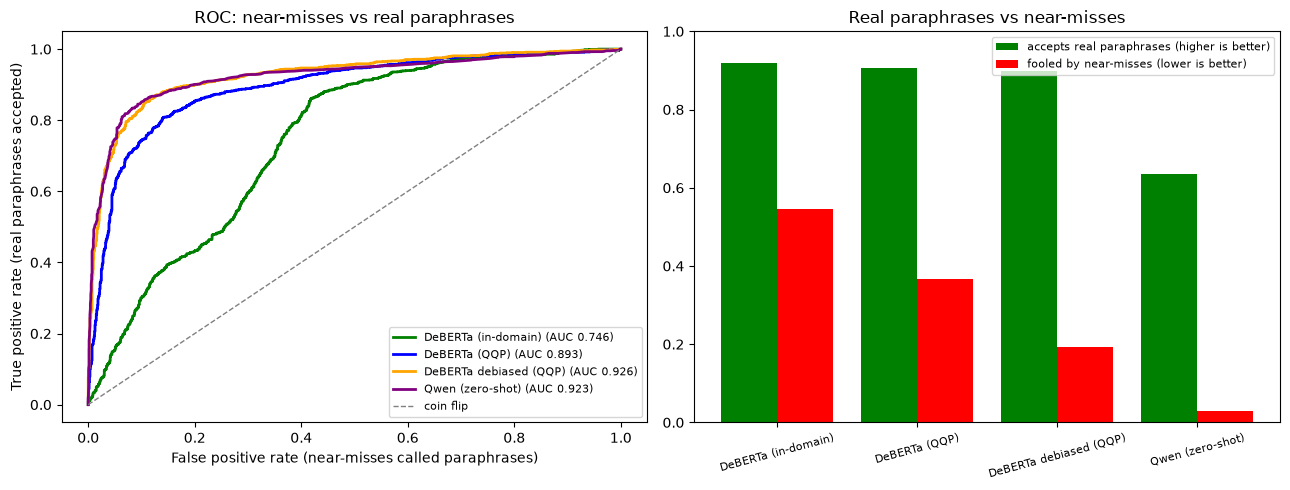

In [47]:
colors = {"DeBERTa (in-domain)": "green", "DeBERTa (QQP)": "blue",
          "DeBERTa debiased (QQP)": "orange", "Qwen (zero-shot)": "purple"}
labels = list(both_probs.keys())
n_pairs = len(clean)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left: one ROC curve per judge
for label in labels:
    fpr, tpr, _ = roc_curve(y_both, both_probs[label])
    axes[0].plot(fpr, tpr, color=colors[label], lw=2,
                 label=f"{label} (AUC {roc_auc_score(y_both, both_probs[label]):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1, label="coin flip")
axes[0].set_xlabel("False positive rate (near-misses called paraphrases)")
axes[0].set_ylabel("True positive rate (real paraphrases accepted)")
axes[0].set_title("ROC: near-misses vs real paraphrases")
axes[0].legend(fontsize=8)

# right: acceptance of real paraphrases next to the fool rate on near-misses
accept = [(both_probs[l][n_pairs:] > 0.5).mean() for l in labels]
fool = [(both_probs[l][:n_pairs] > 0.5).mean() for l in labels]
x = np.arange(len(labels))
axes[1].bar(x - 0.2, accept, 0.4, color="green", label="accepts real paraphrases (higher is better)")
axes[1].bar(x + 0.2, fool, 0.4, color="red", label="fooled by near-misses (lower is better)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=15, fontsize=8)
axes[1].set_ylim(0, 1)
axes[1].set_title("Real paraphrases vs near-misses")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIG_D}/taskD_roc_and_rates.png", dpi=200)
plt.show()

The ROC curves of debiased DeBERTa and Qwen almost overlap and rise well above the standard QQP model, while the in-domain DeBERTa stays closest to the diagonal. The bar chart shows the same trade-off as the table: the three DeBERTa models have similar green bars, so the difference between them lies in how often they are fooled, while Qwen's short red bar comes with a much shorter green bar.

### Confusion matrices
Each matrix shows, for one judge, what share of the near-misses and of the real paraphrases ended up in each predicted class. The top-right cell is the fool rate, and the bottom-left cell is the share of real paraphrases that were wrongly rejected.

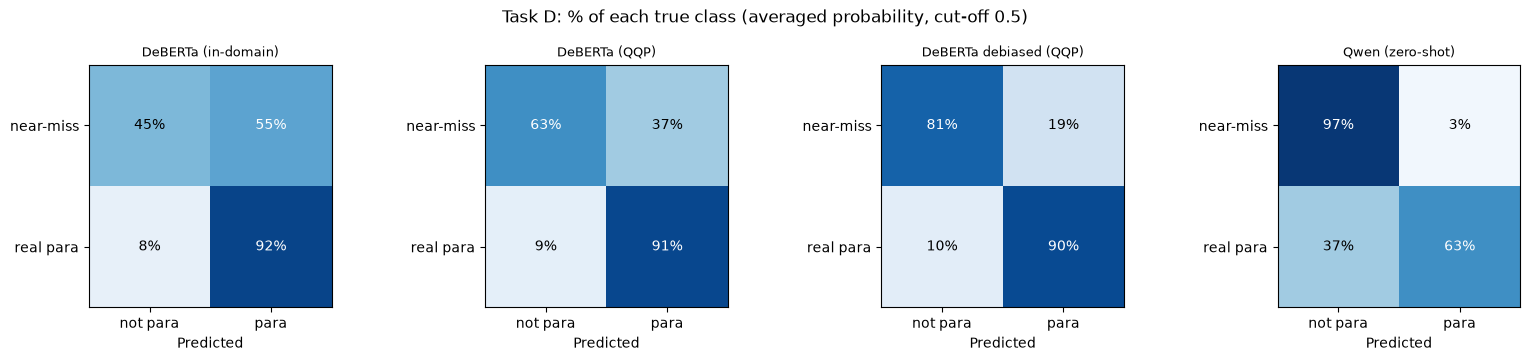

In [48]:
fig, axes = plt.subplots(1, len(labels), figsize=(4 * len(labels), 3.6))
for ax, label in zip(axes, labels):
    pred = (both_probs[label] > 0.5).astype(int)
    cm = confusion_matrix(y_both, pred, labels=[0, 1], normalize="true") * 100   # % of each true class
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)

    # write the percentage in each square
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center",
                    color="white" if cm[i, j] > 50 else "black")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["not para", "para"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["near-miss", "real para"])
    ax.set_xlabel("Predicted")
    ax.set_title(label, fontsize=9)

plt.suptitle("Task D: % of each true class (averaged probability, cut-off 0.5)")
plt.tight_layout()
plt.savefig(f"{FIG_D}/taskD_confusion.png", dpi=200)
plt.show()

The matrices show what kind of mistakes each judge makes. The three DeBERTa models wrongly reject only 8–10% of the real paraphrases, but they accept 55% (in-domain), 37% (QQP) and 19% (debiased) of the near-misses. Qwen makes the opposite mistake: it accepts only 3% of the near-misses but rejects 37% of the real paraphrases. The DeBERTa models lean towards saying "paraphrase", while Qwen leans towards saying "not a paraphrase".

### Fool rate by edit type
This chart shows which kind of edit is hardest to catch. If swaps fool the models far more than number changes or negations, that points back to the word-overlap shortcut, since a swap keeps exactly the same words.

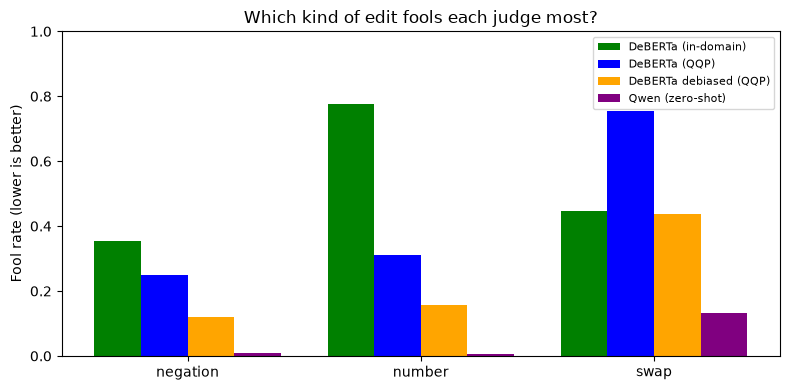

In [49]:
edit_types = sorted(clean["edit_type"].unique())
judges = D_JUDGES + [("qwen", "Qwen (zero-shot)")]
width = 0.2

fig, ax = plt.subplots(figsize=(8, 4))
for j, (name, label) in enumerate(judges):
    rates = []
    for e in edit_types:
        part = clean[clean["edit_type"] == e]
        prob = part["qwen_prob"] if name == "qwen" else part[f"{name}_prob"]
        rates.append((prob > 0.5).mean())
    ax.bar(np.arange(len(edit_types)) + (j - 1.5) * width, rates, width, color=colors[label], label=label)

ax.set_xticks(np.arange(len(edit_types)))
ax.set_xticklabels(edit_types)
ax.set_ylim(0, 1)
ax.set_ylabel("Fool rate (lower is better)")
ax.set_title("Which kind of edit fools each judge most?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_D}/taskD_fool_rate_by_edit.png", dpi=200)
plt.show()

The chart makes the pattern clear: swaps are the hardest edit for the QQP-trained models and for Qwen, while number changes are hardest for the in-domain DeBERTa. Debiasing lowers every orange bar compared with the blue one.

## Task D: Conclusion
Qwen produced 2,279 edited sentences, and 1,260 usable near-miss pairs remained after both cleaning passes. In a hand check of 60 of them, 88.3% really changed the meaning; most of the errors were swaps where two list items or two words joined by "and"/"or" simply traded places.

On these pairs, debiased DeBERTa is the strongest judge overall (accuracy 0.840, AUC 0.926). It is fooled far less often than the standard QQP model (0.210 vs 0.378) while still accepting 89% of real paraphrases, and McNemar's test shows it gets 222 pairs right that the standard model gets wrong, against only 4 the other way. This suggests that the debiasing carries over from PAWS to brand-new trap sentences. Qwen is rarely fooled (0.029), but it rejects about a third of the real paraphrases, and it was judging sentences it had written itself, so its result is likely flattering. Swaps are the hardest edit for every judge except the in-domain DeBERTa, which struggles most with numbers. Finally, BERTScore gives near-misses a higher average score than real paraphrases (0.987 vs 0.964), so it cannot be relied on to catch these traps.

## Saved files
- `taskD_generated.csv`: raw Qwen outputs
- `taskD_all_with_flags.csv`: every output with the filter checks
- `taskD_clean.csv`: the usable near-miss pairs (label 0)
- `taskD_clean_first_pass.csv`: the 1,481 pairs from the first pass, with the reason each removed pair failed the second pass
- `taskD_handcheck.csv`: the 60 pairs for the hand check
- `taskD_text_metrics.csv`: overlap, BLEU and BERTScore by dataset and edit type
- `taskD_text_metrics_vs_real.csv`: BLEU and BERTScore for near-misses vs the real human paraphrases, by dataset
- `taskD_scores.csv`: every judge's probability for every pair (near-misses and real paraphrases), along with the BLEU and BERTScore values
- `taskD_control.csv`: each judge's acceptance rate on real paraphrases next to its fool rate on near-misses
- `taskD_fool_rate_by_dataset.csv`, `taskD_fool_rate_by_edit.csv`: the main results
- `taskD_metadata.json`: model version, prompts and settings
- `taskD_accuracy_f1_auc.csv`: accuracy, F1 and AUC on near-misses plus real paraphrases
- `figures/`: ROC curves, the two rates side by side, confusion matrices and fool rate by edit type

All GPU results are stored in `taskD_scores.csv`, so the tables above can be rebuilt on CPU without loading any model.

# Task C: New sentences

So far, every test sentence comes from MRPC, QQP or PAWS, the same datasets the DeBERTa models were trained on. Task C checks whether the classifiers still recognise paraphrases when the text comes from somewhere else.

Qwen writes 900 candidate sentences in three styles (question, news and encyclopedia) across ten topics, and 280 of them are kept after checking that they are varied and not taken from the three datasets. Qwen then paraphrases each one with a prompt based on the team's Task A prompt. Every pair is therefore a real paraphrase (label 1), so the main measure is the acceptance rate which pertains to how often each judge correctly calls a pair a paraphrase. Higher is better.

Two caveats apply:
- Qwen writes each sentence, paraphrases it and then judges the pair, so its own score is the most likely to be biased in its favour.
- "New" means new to the three datasets, not new to Qwen, since Qwen wrote the sentences. The task really tests whether the trained classifiers generalise beyond the benchmarks they were trained on.

This part reuses the model, settings and helper functions defined in Task D.

In [50]:
OUT_C = "/home/gandhi.gau/NLP_Project/qwen_generation/taskC"
os.makedirs(OUT_C, exist_ok=True)

## Writing the new source sentences
To avoid favouring one dataset, the sentences are written in three styles, each matching one of the datasets:
- **question:** a question someone might post online (like QQP)
- **news:** a sentence from a news report (like MRPC)
- **encyclopedia:** a factual sentence from an encyclopedia article (like PAWS)

Each style is combined with 10 everyday topics. Qwen tends to repeat itself, so it writes 30 sentences for every style and topic pair, and only these source sentences are written at a higher temperature (1.0) for more variety. After repeats are removed, up to 10 are kept per pair, giving at most 100 sentences per style.

The facts in these sentences do not need to be true, since only the paraphrase relation between the two sentences matters.

In [51]:
STYLES = {
    "question": "Write one new question that someone might ask on a Q&A website like Quora, about the given topic.",
    "news": "Write one new sentence in the style of a news report about the given topic. Include a specific name, place, date or number.",
    "encyclopedia": "Write one new factual sentence in the style of an encyclopedia about the given topic. Include a specific name, place, date or number.",
}
SRC_COMMON = " Make it original and 8 to 30 words long. Write in English and output only the sentence."

TOPICS = ["sport", "science", "history", "food and cooking", "technology",
          "health", "travel", "music", "business", "nature and animals"]
PER_CELL = 30        # sentences per style and topic
KEEP_PER_CELL = 10
SRC_TEMP = 1.0       # higher temperature only for writing the new sources, so they repeat less

In [52]:
SRC_FILE = f"{OUT_C}/taskC_sources_raw.csv"

if os.path.exists(SRC_FILE):
    c_raw = pd.read_csv(SRC_FILE, keep_default_na=False)
    print("Loaded saved source sentences:", len(c_raw))
else:
    rows = []
    for k, (style, instruction) in enumerate(STYLES.items()):
        # the same request 30 times per topic, sampling makes every answer different
        inputs = [f"Topic: {t}" for t in TOPICS for _ in range(PER_CELL)]
        topics = [t for t in TOPICS for _ in range(PER_CELL)]

        torch.manual_seed(SEED + 1000 + k)          # fixed seed for each style
        outs = generate_batch(instruction + SRC_COMMON, inputs, temperature=SRC_TEMP)

        for t, o in zip(topics, outs):
            rows.append({"style": style, "topic": t, "source": o})
        print(f"{style}: {len(outs)} sentences written")

    c_raw = pd.DataFrame(rows)
    c_raw.to_csv(SRC_FILE, index=False)

c_raw.head(6)

Loaded saved source sentences: 900


,style,topic,source
0,question,sport,What are the health benefits of regularly play...
1,question,sport,What are the best strategies for training to p...
2,question,sport,How have sports teams adapted their strategies...
3,question,sport,What are some effective strategies for prevent...
4,question,sport,What are the health benefits of playing team s...
5,question,sport,How has sportsmanship evolved with the increas...


## Checking the new sentences
Before paraphrasing, each sentence is checked, and it is removed if:
- it is empty or starts with extra text such as "Here is…"
- it doesn't match its style (a question that doesn't end with "?", or a news or encyclopedia sentence that does)
- it is too short or too long (fewer than 6 or more than 40 words)
- it is almost the same as another generated sentence (Jaccard overlap of 0.6 or more)
- it already appears in MRPC, QQP or PAWS, either word for word or as a very close match (TF-IDF cosine similarity of 0.8 or more with any sentence in any split)

The last check is what makes these sentences genuinely new to the three datasets.

In [53]:
c_raw["source"] = c_raw["source"].astype(str).str.strip()
src_s = c_raw["source"]

checks = pd.DataFrame(index=c_raw.index)
checks["empty_or_extra"] = (src_s == "") | src_s.str.contains(r"^(?:here|sure|certainly)\b|sentence:",
                                                              case=False, regex=True)

# questions should end with "?" and the other two styles should not
is_question = src_s.str.endswith("?")
checks["wrong_style"] = ((c_raw["style"] == "question") & ~is_question) | ((c_raw["style"] != "question") & is_question)

n_words = src_s.apply(lambda x: len(words(x)))
checks["bad_length"] = (n_words < 6) | (n_words > 40)

# For near-duplicates among the generated sentences: keep the first one, drop later ones that are too similar
dup = []
kept_so_far = []
for text in src_s:
    is_dup = any(jaccard(text, other) >= 0.6 for other in kept_so_far)
    dup.append(is_dup)
    if not is_dup:
        kept_so_far.append(text)
checks["near_duplicate"] = dup

In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer

# every sentence from every split of the three datasets
all_sents = []
for ds in ["mrpc", "qqp", "paws"]:
    for sp in ["train", "dev", "test"]:
        df = pd.read_csv(f"{SPLITS}/{ds}_{sp}.csv", keep_default_na=False)
        all_sents += df["sentence1"].astype(str).tolist() + df["sentence2"].astype(str).tolist()
print("Dataset sentences to compare against:", len(all_sents))

Dataset sentences to compare against: 228636


In [ ]:
# exact matches, ignoring case and punctuation
known = set(" ".join(words(x)) for x in all_sents)
checks["in_dataset"] = [" ".join(words(x)) in known for x in src_s]

# very close matches: highest TF-IDF cosine similarity with any dataset sentence
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(all_sents + src_s.tolist())
X_data = vec.transform(all_sents)
X_new = vec.transform(src_s)

In [56]:
max_sim = []
for i in range(0, X_new.shape[0], 50):           # 50 sentences at a time to save memory
    sims = X_new[i:i + 50] @ X_data.T
    max_sim += sims.max(axis=1).toarray().ravel().tolist()
c_raw["max_sim_to_data"] = np.round(max_sim, 3)
checks["close_to_dataset"] = c_raw["max_sim_to_data"] >= 0.8

In [57]:
c_raw["ok"] = ~checks.any(axis=1)

# how many sentences each check removed, per style
src_summary = checks.groupby(c_raw["style"]).sum()
src_summary["ok"] = c_raw.groupby("style")["ok"].sum()
display(src_summary)

# keep 10 per style and topic
c_src = c_raw[c_raw["ok"]].groupby(["style", "topic"]).head(KEEP_PER_CELL).reset_index(drop=True)
c_src.to_csv(f"{OUT_C}/taskC_sources.csv", index=False)
print("Source sentences kept:", len(c_src))
print(c_src.groupby("style").size())

,empty_or_extra,wrong_style,bad_length,near_duplicate,in_dataset,close_to_dataset,ok
style,,,,,,,
encyclopedia,0,0,0,108,0,0,192
news,0,0,0,60,0,0,240
question,0,0,0,199,0,0,101


Source sentences kept: 280
style
encyclopedia    100
news            100
question         80
dtype: int64


None of the generated sentences matched, or came close to, any sentence in MRPC, QQP or PAWS, so every source is new to the three datasets. The main problem was repetition: of the 300 questions, 199 were near-duplicates of an earlier one, compared with 60 of the news sentences and 108 of the encyclopedia sentences. As a result, only 80 questions were kept, since some topics did not have 10 different questions left, while news and encyclopedia kept 100 each.

To show that the sentences are varied and not near-copies of each other, the table below gives the average length and the distinct-2 score for each style. Distinct-2 is the share of word pairs (bigrams) that are unique across all sentences of that style, so a value closer to 1 means more variety.

In [58]:
def distinct2(texts):
    # unique word pairs / all word pairs
    bigrams = []
    for t in texts:
        w = words(t)
        bigrams += list(zip(w, w[1:]))
    return len(set(bigrams)) / max(len(bigrams), 1)

In [59]:
variety = []
for style, part in c_src.groupby("style"):
    variety.append({"style": style, "sentences": len(part),
                    "avg words": round(part["source"].apply(lambda x: len(words(x))).mean(), 1),
                    "distinct-2": round(distinct2(part["source"]), 3),
                    "max similarity to datasets": part["max_sim_to_data"].max()})
pd.DataFrame(variety)

,style,sentences,avg words,distinct-2,max similarity to datasets
0,encyclopedia,100,17.7,0.756,0.362
1,news,100,19.8,0.715,0.386
2,question,80,11.4,0.626,0.748


## Paraphrasing the new sentences
Each new sentence is paraphrased with a prompt based on the team's Task A prompt, using the same generation settings. The prompt also tells Qwen to keep statements as statements and questions as questions, because Qwen was sometimes turning statements into questions.

In [60]:
# paraphrase prompt based on the team's Task A prompt
PARA_PROMPT = ("Rewrite the sentence with different words and structure, but keep the exact same meaning. "
               "Keep all names, numbers, places, dates and relations unchanged, and do not add or remove information. "
               "A statement must stay a statement, and a question must stay a question; do not answer it. "
               "Write in English and output only the paraphrase.")

PARA_FILE = f"{OUT_C}/taskC_paraphrased.csv"

if os.path.exists(PARA_FILE):
    c_pairs = pd.read_csv(PARA_FILE, keep_default_na=False)
    print("Loaded saved paraphrases:", len(c_pairs))
else:
    outs = []
    for i in range(0, len(c_src), BS):
        torch.manual_seed(SEED + 2000 + i // BS)     # fixed seed for each batch
        outs += generate_batch(PARA_PROMPT, c_src["source"].iloc[i:i + BS].tolist())
    c_pairs = c_src.assign(paraphrase=outs)
    c_pairs.to_csv(PARA_FILE, index=False)
    print("Paraphrased", len(c_pairs), "sentences")

meta_c = {"task": "C: new sentences and their paraphrases", "model": HF_ID, "revision": REVISION,
          "dtype": "bfloat16", "gen_config": GEN_CFG, "seed": SEED, "styles": STYLES,
          "source_prompt_suffix": SRC_COMMON, "topics": TOPICS, "paraphrase_prompt": PARA_PROMPT,
          "date": datetime.datetime.now().isoformat(timespec="seconds")}
json.dump(meta_c, open(f"{OUT_C}/taskC_metadata.json", "w"), indent=1)

Loaded saved paraphrases: 280


## Cleaning the paraphrases
The same kind of checks as before are applied. A pair is removed if the paraphrase is empty, an exact copy of the source, starts with extra text, changes the sentence type (a question becomes a statement, or the other way round), or has a very different length (less than 0.5 or more than 2 times the source). The length range is wider than in Task D, because a good paraphrase can legitimately be a bit shorter or longer than the original.

In [ ]:
# checking if every paraphrase is text, with no extra spaces at the ends
c_pairs["paraphrase"] = c_pairs["paraphrase"].astype(str).str.strip()
a = c_pairs["source"]
b = c_pairs["paraphrase"]

# one True/False column per check, where True means the pair fails that check
pflags = pd.DataFrame(index=c_pairs.index)

# no output was returned
pflags["empty"] = b == ""

# the output is identical to the source, so no rewording took place
pflags["copy"] = b.str.lower() == a.str.lower()

# the output includes extra text
pflags["extra_text"] = b.str.contains(r"^(?:here|sure|certainly)\b|paraphrase:", case=False, regex=True)

# the sentence type changed 
pflags["type_changed"] = a.str.endswith("?") != b.str.endswith("?")

# the length changed too much 
ratio = b.str.len() / a.str.len()
pflags["length_change"] = (ratio < 0.5) | (ratio > 2.0)

# a pair is kept only if it passes every check
c_pairs["keep"] = ~pflags.any(axis=1)

# number of pairs removed by each check and the number kept, for each style
display(pflags.groupby(c_pairs["style"]).sum().assign(kept=c_pairs.groupby("style")["keep"].sum()))

,empty,copy,extra_text,type_changed,length_change,kept
style,,,,,,
encyclopedia,0,0,0,0,0,100
news,0,0,0,0,0,100
question,0,0,0,1,0,79


In [62]:
c_clean = c_pairs[c_pairs["keep"]].reset_index(drop=True)
c_clean["label"] = 1      # every pair is a paraphrase by design
c_clean["overlap"] = [jaccard(x, y) for x, y in zip(c_clean["source"], c_clean["paraphrase"])]
c_clean.to_csv(f"{OUT_C}/taskC_clean.csv", index=False)
print("Usable paraphrase pairs:", len(c_clean))

Usable paraphrase pairs: 279


In [3]:
# a few examples 
for _, r in c_clean.sample(6, random_state=SEED).iterrows():
    print(f"\n[{r['style']} | {r['topic']}]\n  SENTENCE: {r['source']}\n  PARAPHRASE: {r['paraphrase']}")


[question | food and cooking]
  SENTENCE: What are some creative ways to use leftover mashed potatoes?
  PARAPHRASE: How about some inventive uses for remaining mashed potatoes?

[news | technology]
  SENTENCE: Microsoft launches its new AI-powered operating system, Windows 11, on October 5, 2021.
  PARAPHRASE: On October 5, 2021, Microsoft introduces its new operating system, Windows 11, which is powered by artificial intelligence.

[encyclopedia | history]
  SENTENCE: The Treaty of Tordesillas, signed in 1494, divided newly discovered lands outside Europe between the Portuguese Empire and the Spanish Empire.
  PARAPHRASE: In 1494, the Treaty of Tordesillas allocated recently discovered territories outside Europe to the Portuguese Empire and the Spanish Empire.

[news | travel]
  SENTENCE: According to travel experts, Bangkok's Suvarnabhumi Airport handled over 50 million passengers in 2019 before the pandemic struck.
  PARAPHRASE: In the opinion of travel specialists, Bangkok's Suva

## Hand check
The automatic checks only catch obvious problems, so, as in Task D, a small sample is also checked by hand: 17 pairs per style, 51 in total. They are saved to `taskC_handcheck.csv` with an empty `same_meaning` column, where each pair gets a 1 if the paraphrase keeps the meaning and a 0 if it does not. After the file is filled in, re-running the cell below shows the result. The file is only created once, so the answers are never overwritten.

In [4]:
HAND_C = f"{OUT_C}/taskC_handcheck.csv"

if not os.path.exists(HAND_C):
    sample = c_clean.groupby("style").sample(n=17, random_state=SEED)
    sample = sample[["style", "topic", "source", "paraphrase"]].copy()
    sample["same_meaning"] = ""
    sample.to_csv(HAND_C, index=False)
    print("Saved", len(sample), "pairs to", HAND_C, "for checking")

hand_c = pd.read_csv(HAND_C, keep_default_na=False)
filled = hand_c[hand_c["same_meaning"].astype(str).str.strip() != ""]
if len(filled) > 0:
    filled = filled.assign(same_meaning=filled["same_meaning"].astype(int))
    print(f"Checked {len(filled)} pairs: meaning kept in {filled['same_meaning'].mean():.1%}")
    display(filled.groupby("style")["same_meaning"].mean().round(2))
    
    # Print the faulty paraphrases so the errors can be seen directly
    print("\nPairs where the meaning was not kept:")
    for _, r in filled[filled["same_meaning"] == 0].iterrows():
        print(f"  [{r['style']} | {r['topic']}]")
        print(f"  SENTENCE: {r['source']}")
        print(f"  PARAPHRASE: {r['paraphrase']}\n")
else:
    print("Hand check not filled in yet")

Checked 51 pairs: meaning kept in 92.2%


style
encyclopedia    1.00
news            0.88
question        0.88
Name: same_meaning, dtype: float64


Pairs where the meaning was not kept:
  [news | nature and animals]
  SENTENCE: On October 15, bird watchers spotted an endangered whooping crane near the Rocky Mountain National Park.
  PARAPHRASE: On October 15, bird watchers observed a critically endangered whooping crane in the vicinity of Rocky Mountain National Park.

  [news | business]
  SENTENCE: Tech giant Intel announced plans to invest $20 billion in a new chip manufacturing complex in Arizona by 2026.
  PARAPHRASE: By 2026, tech giant Intel will reveal intentions to allocate $20 billion for establishing a novel chip production facility in Arizona.

  [question | travel]
  SENTENCE: What are some budget-friendly tips for traveling to Europe?
  PARAPHRASE: Could you look into some cost-effective suggestions for traveling around Europe?

  [question | science]
  SENTENCE: What are some groundbreaking discoveries in science that have changed our understanding of the universe?
  PARAPHRASE: Could you inquire about some revolut

In 47 of the 51 checked pairs (92.2%), the paraphrase kept the meaning. All encyclopedia pairs were correct, and news and questions were each 88% correct. The errors either added or changed information ("endangered" -> "critically endangered", "announced plans… by 2026" -> "will reveal intentions by 2026"), or turned a question into a request to the reader ("Could you look into…"). So a small share of these "paraphrases" are not true paraphrases, and a judge that accepted them was actually wrong.

## Text metrics
The same two metrics as in Task D are used, but here the hoped-for result is the opposite:
- **BERTScore F1:** should be high, because a paraphrase should keep the meaning.
- **BLEU:** should be low, because a good paraphrase rewords the sentence rather than copying it.

High BERTScore together with low BLEU is the sign of a real paraphrase: same meaning, new wording.

In [65]:
c_clean["bleu"] = [sacrebleu.sentence_bleu(y, [x]).score for x, y in zip(c_clean["source"], c_clean["paraphrase"])]

_, _, F1 = bert_score(c_clean["paraphrase"].tolist(), c_clean["source"].tolist(),
                      lang="en", batch_size=64, device="cuda", verbose=False)
c_clean["bertscore_f1"] = F1.numpy()

c_metrics = c_clean.groupby("style")[["overlap", "bleu", "bertscore_f1"]].mean()
c_metrics.loc["all"] = c_clean[["overlap", "bleu", "bertscore_f1"]].mean()
c_metrics = c_metrics.round(3)
c_metrics.to_csv(f"{OUT_C}/taskC_text_metrics.csv")
c_metrics


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 10684.55it/s]


[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,overlap,bleu,bertscore_f1
style,,,
encyclopedia,0.605,31.530,0.967
news,0.567,34.051,0.971
question,0.350,16.355,0.950
all,0.519,28.137,0.964


The paraphrases stay close in meaning to their sources (BERTScore 0.964) while reusing far fewer words than the Task D near-misses (BLEU 28.1 vs 77.5). Questions were reworded the most (BLEU 16.4, overlap 0.350), often by changing the form of the question, eg:"What are some creative ways to use leftover mashed potatoes?" -> "How about some inventive uses for remaining mashed potatoes?".

## Do the classifiers accept the new paraphrases?
These sentences do not come from any training set, so there is no "in-domain" DeBERTa for them. Instead, every pair is scored by all three standard DeBERTa models (trained on MRPC, QQP and PAWS), as well as the debiased DeBERTa and Qwen. Using all three DeBERTa models also shows whether each one does best on the style closest to its own training data, for example the QQP model on the questions.

The MRPC and PAWS models were trained on Treebank-style text, where punctuation is split off from words. To keep the comparison fair, both sentences are converted to that style before these two models score them. The QQP-trained models and Qwen receive normal text, which matches how QQP is written.

In [66]:
def styled(texts, trained_on):
    # MRPC and PAWS models were trained on Treebank-style text, so they get the same style here
    if trained_on in ("mrpc", "paws"):
        return [normalise(t, trained_on) for t in texts]
    return list(texts)

ca = c_clean["source"].tolist()
cb = c_clean["paraphrase"].tolist()

for s in SEEDS:
    for ds in ["mrpc", "qqp", "paws"]:
        c_clean[f"deb_{ds}_s{s}"] = deberta_probs(checkpoints[(ds, s)], styled(ca, ds), styled(cb, ds))
    c_clean[f"deb_debias_s{s}"] = deberta_probs(checkpoints[("qqp_debias", s)], ca, cb)
    print("seed", s, "done")

c_clean["qwen_prob"] = qwen_probs(ca, cb)
c_clean.to_csv(f"{OUT_C}/taskC_scores.csv", index=False)
print("Scores saved for", len(c_clean), "pairs")


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 14412.44it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 11344.15it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 12563.57it/s]

... (36 outputs left out)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 16926.71it/s]

seed 46 done


Scores saved for 279 pairs


## Results: acceptance rate
The acceptance rate is the share of pairs a judge calls a paraphrase (probability above 0.5). For the DeBERTa models it is shown as mean ± std over the 5 seeds. Qwen has a single run.

In [67]:
C_JUDGES = [("deb_mrpc", "DeBERTa (MRPC)"), ("deb_qqp", "DeBERTa (QQP)"),
            ("deb_paws", "DeBERTa (PAWS)"), ("deb_debias", "DeBERTa debiased (QQP)")]

def accept_table(df, group_col):
    rows = []
    for g, part in df.groupby(group_col):
        row = {group_col: g, "pairs": len(part)}
        for name, label in C_JUDGES:
            rates = [(part[f"{name}_s{s}"] > 0.5).mean() for s in SEEDS]
            row[label] = f"{np.mean(rates):.3f} ± {np.std(rates, ddof=1):.3f}"
        row["Qwen (zero-shot)"] = f"{(part['qwen_prob'] > 0.5).mean():.3f}"
        rows.append(row)
    return pd.DataFrame(rows)

c_results = pd.concat([accept_table(c_clean, "style"),
                       accept_table(c_clean.assign(style="all"), "style")], ignore_index=True)
c_results.to_csv(f"{OUT_C}/taskC_acceptance.csv", index=False)
print("Acceptance rate on new paraphrases (higher is better)")
c_results

Acceptance rate on new paraphrases (higher is better)


,style,pairs,DeBERTa (MRPC),DeBERTa (QQP),DeBERTa (PAWS),DeBERTa debiased (QQP),Qwen (zero-shot)
0,encyclopedia,100,1.000 ± 0.000,0.994 ± 0.005,0.982 ± 0.008,0.992 ± 0.008,0.990
1,news,100,1.000 ± 0.000,1.000 ± 0.000,0.980 ± 0.012,1.000 ± 0.000,0.980
2,question,79,0.942 ± 0.007,1.000 ± 0.000,0.977 ± 0.019,1.000 ± 0.000,0.987
3,all,279,0.984 ± 0.002,0.998 ± 0.002,0.980 ± 0.009,0.997 ± 0.003,0.986


Every judge accepts almost all of the new paraphrases (98.0–99.8% overall), so the trained classifiers still recognise paraphrases in text from outside their datasets. The only clear drop is the MRPC model on questions (0.942), which is the style furthest from its news-based training data. Both QQP-trained models score 1.000 on questions, the style closest to their own. Debiasing costs almost nothing here (0.997 vs 0.998 overall).

## Charts
The first chart shows how often each judge accepts the new paraphrases, split by style. If a DeBERTa model does clearly better on the style closest to its own training data (for example the QQP model on questions), that suggests it depends on the look of its training text and not only on meaning.

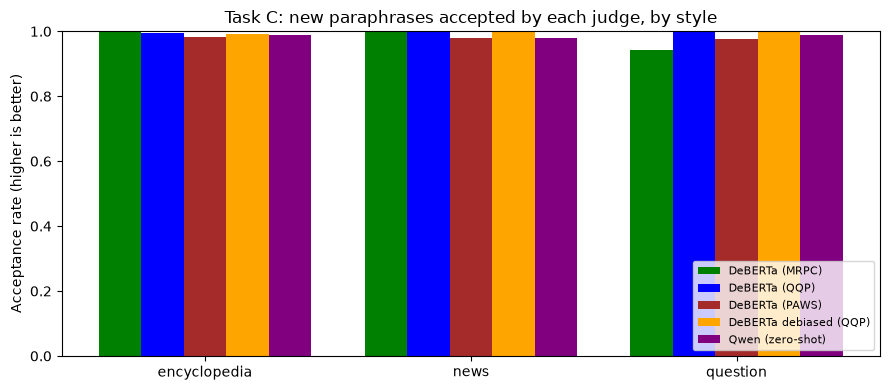

In [68]:
FIG_C = f"{OUT_C}/figures"
os.makedirs(FIG_C, exist_ok=True)

c_colors = {"DeBERTa (MRPC)": "green", "DeBERTa (QQP)": "blue", "DeBERTa (PAWS)": "brown",
            "DeBERTa debiased (QQP)": "orange", "Qwen (zero-shot)": "purple"}
styles = sorted(c_clean["style"].unique())
c_judges = C_JUDGES + [("qwen", "Qwen (zero-shot)")]
width = 0.16

fig, ax = plt.subplots(figsize=(9, 4))
for j, (name, label) in enumerate(c_judges):
    rates = []
    for st in styles:
        part = c_clean[c_clean["style"] == st]
        if name == "qwen":
            rates.append((part["qwen_prob"] > 0.5).mean())
        else:
            # average of the 5 seeds
            rates.append(np.mean([(part[f"{name}_s{s}"] > 0.5).mean() for s in SEEDS]))
    ax.bar(np.arange(len(styles)) + (j - 2) * width, rates, width, color=c_colors[label], label=label)

ax.set_xticks(np.arange(len(styles)))
ax.set_xticklabels(styles)
ax.set_ylim(0, 1)
ax.set_ylabel("Acceptance rate (higher is better)")
ax.set_title("Task C: new paraphrases accepted by each judge, by style")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_C}/taskC_acceptance_by_style.png", dpi=200)
plt.show()

All the bars sit near the top, so this task cannot separate the judges: accepting real paraphrases is easy for all of them. The results need to be read together with Task D. For example, the MRPC model accepts 98.4% of the Task C paraphrases, but in Task D it also accepted 99.4% of the MRPC near-misses. A high acceptance rate on its own therefore does not show that a model understands meaning; it may simply say "paraphrase" to almost everything.

## Paraphrases vs near-misses on the text metrics
This plot brings Tasks C and D together. Every pair is placed by its BLEU score (how many words were copied from the source) and its BERTScore (how close the meaning is). Real paraphrases, whether written by Qwen or by people, are expected to sit on the left with low BLEU, while the near-misses are expected to sit on the right with high BLEU. Wherever the groups overlap, the text metrics alone can't tell a paraphrase from a trap.

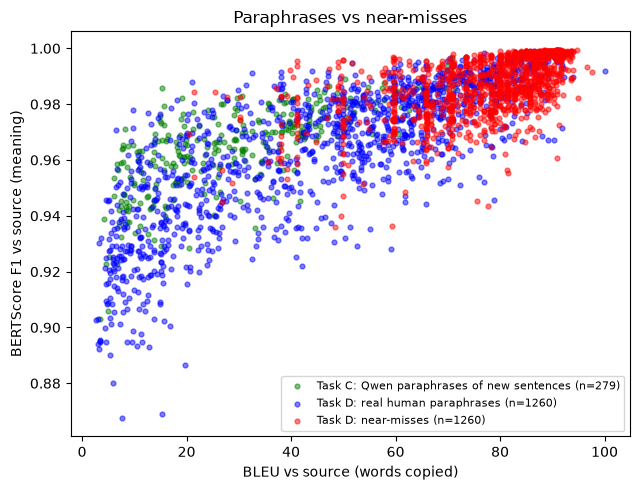

In [69]:
fig, ax = plt.subplots(figsize=(6.5, 5))

# Qwen's paraphrases of the new sentences (Task C)
ax.scatter(c_clean["bleu"], c_clean["bertscore_f1"], s=12, alpha=0.5, color="green",
           label=f"Task C: Qwen paraphrases of new sentences (n={len(c_clean)})")

# the dataset's own human paraphrases (Task D control)
ax.scatter(clean["ref_bleu"], clean["ref_bertscore_f1"], s=12, alpha=0.5, color="blue",
           label=f"Task D: real human paraphrases (n={len(clean)})")

# the near-misses (Task D)
ax.scatter(clean["bleu"], clean["bertscore_f1"], s=12, alpha=0.5, color="red",
           label=f"Task D: near-misses (n={len(clean)})")

ax.set_xlabel("BLEU vs source (words copied)")
ax.set_ylabel("BERTScore F1 vs source (meaning)")
ax.set_title("Paraphrases vs near-misses")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_C}/bleu_vs_bertscore.png", dpi=200)
plt.show()

The plot shows a clear pattern along BLEU. The red near-misses are packed into the top-right corner (mostly BLEU 60–95 and BERTScore above 0.96), Qwen's green Task C paraphrases sit on the left (mostly BLEU below 50), and the blue real human paraphrases are spread across the whole range. On BERTScore, however, the groups overlap heavily, and the near-misses sit at the very top, even above most of the real paraphrases, although their meaning has changed (average 0.987 vs 0.964). The red and blue points also overlap a lot between BLEU 60 and 90, where many real paraphrases (mostly from PAWS) copy as many words as the near-misses. Neither metric can therefore tell a paraphrase from a near-miss: both mainly reward copied words, which is why trained judges are needed.

## Task C: Conclusion
Qwen wrote 900 candidate sentences in three dataset styles, and 280 were kept after removing repeats; none of them appear in MRPC, QQP or PAWS. Qwen then paraphrased each one, and 279 pairs passed the checks. In a hand check of 51 of them, 92.2% kept the meaning.

Every judge accepts 98–100% of these pairs overall, so the trained DeBERTa models handle text from outside their benchmarks well, with only a small drop for the MRPC model on questions (0.942). Since all judges are near the ceiling, this task cannot rank them on its own. Read together with Task D, debiased DeBERTa is the most balanced judge: it accepts new paraphrases as readily as the standard QQP model (0.997 vs 0.998) while being fooled far less by near-misses.

**Limitations:**
- Qwen wrote, paraphrased and judged these pairs itself, so its own score is likely flattering.
- The generated sentences repeat some themes, which the near-duplicate filter only partly removed, especially for questions.

## Saved files (Task C)
- `taskC_sources_raw.csv`: every sentence Qwen wrote, before checking
- `taskC_sources.csv`: the new source sentences that passed the checks
- `taskC_paraphrased.csv`: the sources with Qwen's paraphrases
- `taskC_clean.csv`: the usable paraphrase pairs (label 1)
- `taskC_handcheck.csv`: the 51 pairs for the hand check
- `taskC_text_metrics.csv`: BLEU and BERTScore by style
- `taskC_scores.csv`: every judge's probability for every pair
- `taskC_acceptance.csv`: the main results
- `taskC_metadata.json`: model version, prompts and settings
- `figures/`: acceptance rate by style, and BLEU vs BERTScore for Task C paraphrases, real paraphrases and near-misses